In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

First 5 Records:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape:
(27528, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 27528 entries, 0 to 27527
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender           

In [5]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (27528, 8)
Target Shape: (27528,)

Target Distribution:
diabetes
0    25168
1     2360
Name: count, dtype: int64


In [6]:
categorical_columns = ['gender', 'smoking_history']

numerical_columns = [
    'age',
    'hypertension',
    'heart_disease',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

Categorical Columns: ['gender', 'smoking_history']
Numerical Columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ],
    remainder='passthrough'
)

print("Preprocessor Created Successfully!")

Preprocessor Created Successfully!


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (22022, 8)
Testing Data: (5506, 8)


In [9]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Preprocessing Completed Successfully!")
print("Processed Training Data:", X_train.shape)
print("Processed Testing Data:", X_test.shape)

Preprocessing Completed Successfully!
Processed Training Data: (22022, 15)
Processed Testing Data: (5506, 15)


In [10]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [11]:
y_pred = rf.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Model Accuracy:", accuracy * 100, "%")

Random Forest Model Accuracy: 97.11224119142753 %


In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[5012   22]
 [ 137  335]]


In [14]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      5034
           1       0.94      0.71      0.81       472

    accuracy                           0.97      5506
   macro avg       0.96      0.85      0.90      5506
weighted avg       0.97      0.97      0.97      5506



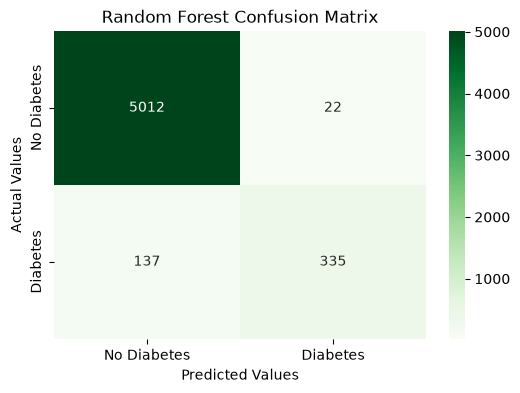

In [15]:
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [16]:
feature_names = preprocessor.get_feature_names_out()

importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
                             Feature    Importance
13            remainder__HbA1c_level  3.937700e-01
14    remainder__blood_glucose_level  3.196039e-01
12                    remainder__bmi  1.202144e-01
9                     remainder__age  1.060761e-01
10           remainder__hypertension  1.584988e-02
11          remainder__heart_disease  1.235967e-02
3       cat__smoking_history_No Info  5.129543e-03
6        cat__smoking_history_former  5.129064e-03
7         cat__smoking_history_never  4.908716e-03
1                   cat__gender_Male  4.007980e-03
0                 cat__gender_Female  3.941577e-03
8   cat__smoking_history_not current  3.340459e-03
4       cat__smoking_history_current  2.935702e-03
5          cat__smoking_history_ever  2.732417e-03
2                  cat__gender_Other  5.688521e-07


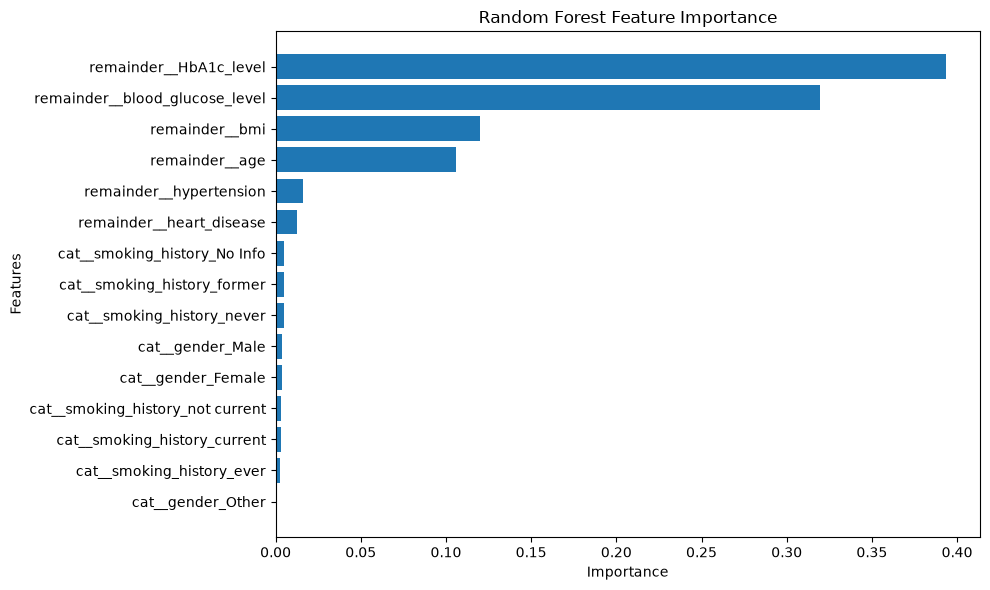

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusion:

The Random Forest Classification algorithm was successfully implemented on the diabetes prediction dataset. The dataset was preprocessed using OneHotEncoder to convert categorical features into numerical form. The dataset was divided into 80% training and 20% testing data. A Random Forest classifier containing 100 decision trees was trained to predict diabetes. The model performance was evaluated using accuracy, confusion matrix, precision, recall and F1-score. Feature importance was also calculated to identify the most influential features.